In [71]:
import numpy as np
import matplotlib.pyplot as plt
import uproot

In [38]:
# 1. Carica il file .npz
# Sostituisci 'tuo_file.npz' con il nome reale del tuo file
data = np.load('../data/not_calibrated/run433171958_261021172134.npz') #dati non calibrati
# data = np.load('../data/run433171958_261021172134.npz') #dati calibrati


# 2. Scopri quali array sono salvati all'interno dell'archivio
print("Nomi degli array nel file:", data.files)

# 3. Leggi e stampa un array specifico (usando il nome trovato al punto 2)
# Ad esempio, se tra i nomi c'è 'arr_0':
nome_array = data.files[0] 
array_selezionato = data[nome_array]

print(f"\nContenuto dell'array '{nome_array}':")
print(array_selezionato)

# (Opzionale) Puoi vedere la forma (dimensioni) e il tipo di dati:
print("Dimensioni (shape):", array_selezionato.shape)
print("Tipo di dati:", array_selezionato.dtype)

Nomi degli array nel file: ['ADC_pixels', 'scope_channels']

Contenuto dell'array 'ADC_pixels':
[[[[241.5921  241.82071 241.8969  ... 241.32541 241.7064  242.1255 ]
   [231.8004  232.1433  232.8672  ... 232.3719  232.6386  233.4387 ]
   [225.5901  224.33281 225.1329  ... 226.3902  225.5139  225.8568 ]
   [243.8781  244.71631 243.8781  ... 245.8212  246.3927  246.20221]]

  [[230.505   230.2764  229.70491 ... 230.12401 229.0572  230.16211]
   [  0.        0.        0.      ...   0.        0.        0.     ]
   [  0.        0.        0.      ...   0.        0.        0.     ]
   [248.10721 248.14531 248.64061 ... 249.3264  248.7168  248.2977 ]]

  [[232.5243  231.3051  232.1814  ... 230.2764  229.8573  230.0859 ]
   [  0.        0.        0.      ...   0.        0.        0.     ]
   [  0.        0.        0.      ...   0.        0.        0.     ]
   [243.9543  242.81131 242.81131 ... 244.1067  243.72571 242.8875 ]]

  [[244.22101 244.4877  244.8687  ... 244.5258  244.3734  244.5258 ]
 

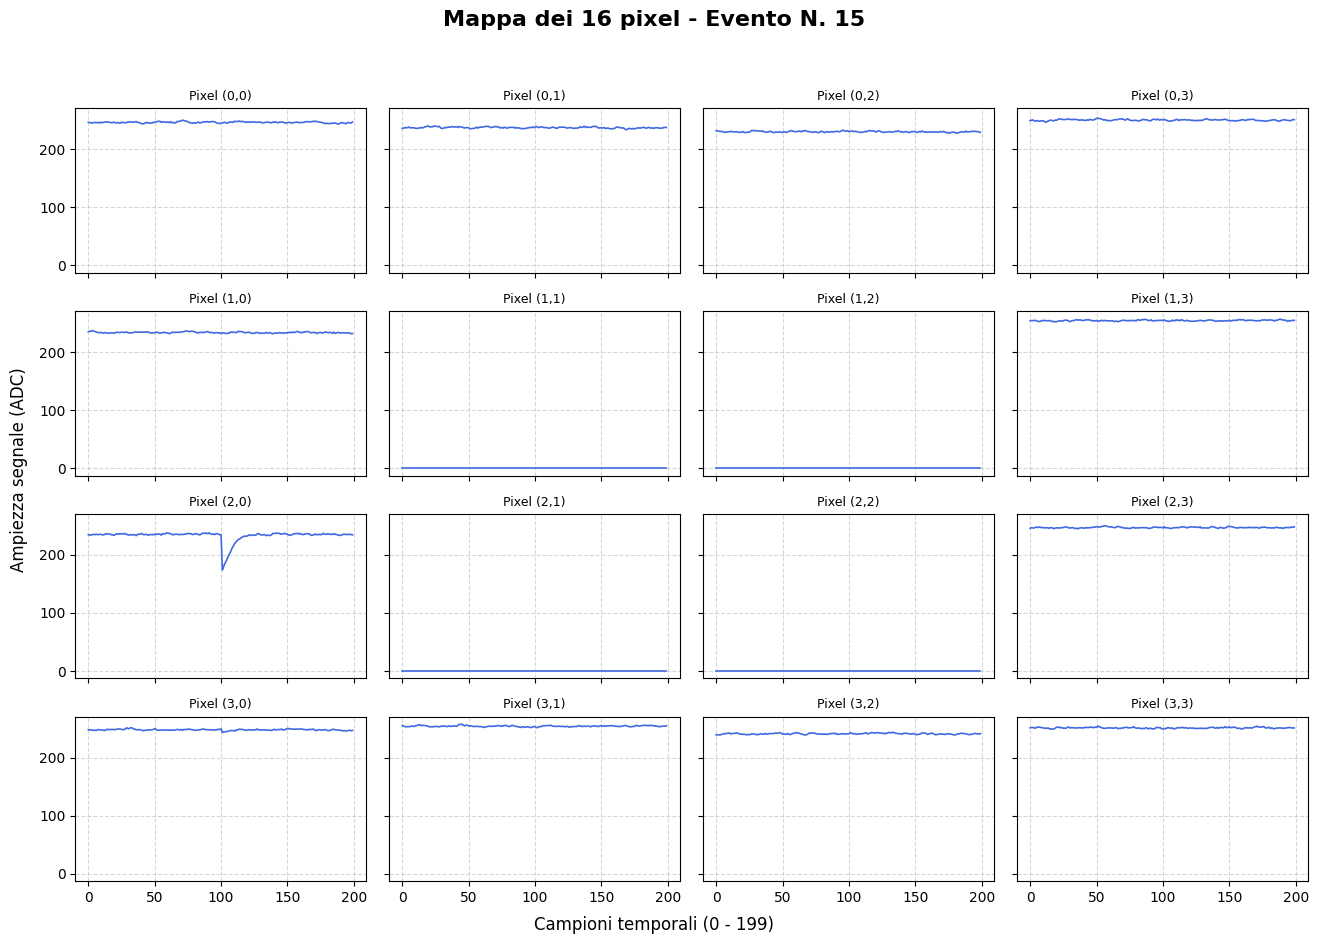

In [39]:
adc_pixels = data['ADC_pixels']  # Forma: (10001, 4, 4, 200)

# ==========================================
# VARIABILE DELL'EVENTO DA VISUALIZZARE
# Cambia questo numero (da 0 a 10000) per esplorare i diversi eventi
evento_scelto = 15 
# ==========================================

# Estrae i dati relativi solo all'evento scelto (forma: 4, 4, 200)
dati_evento = adc_pixels[evento_scelto]

# 2. Crea una figura con una griglia 4x4 di subplot
# sharex=True e sharey=True mantengono gli assi uguali per facilitare il confronto
fig, axes = plt.subplots(4, 4, figsize=(14, 10), sharex=True, sharey=True)

# 3. Ciclo per popolare i 16 subplot (4 righe, 4 colonne)
for i in range(4):
    for j in range(4):
        ax = axes[i, j]
        
        # Estrae i 200 campioni temporali per il pixel alla posizione (i, j)
        segnale_pixel = dati_evento[i, j, :]
        
        # Plot del segnale
        ax.plot(segnale_pixel, color='royalblue', linewidth=1.2)
        
        # Etichetta e griglia per ogni pixel
        ax.set_title(f"Pixel ({i},{j})", fontsize=9)
        ax.grid(True, linestyle='--', alpha=0.5)

# Aggiunge etichette generali alla griglia
fig.text(0.5, 0.04, 'Campioni temporali (0 - 199)', ha='center', fontsize=12)
fig.text(0.04, 0.5, 'Ampiezza segnale (ADC)', va='center', rotation='vertical', fontsize=12)

# Titolo principale con il numero dell'evento dinamico
plt.suptitle(f"Mappa dei 16 pixel - Evento N. {evento_scelto}", fontsize=16, fontweight='bold', y=0.96)

# Ottimizza la spaziatura
plt.tight_layout(rect=[0.05, 0.05, 0.98, 0.93])

# Mostra il grafico
plt.show()

In [27]:
# ==========================================
# DEFINISCI LA SOGLIA MINIMA
# ==========================================
soglia_minima = 180.0

# 2. Crea una maschera spaziale (4x4) per escludere i pixel 5, 6, 9, 10
# In una griglia 4x4 (indicizzata da 0 a 3), questi formano il quadrato centrale:
# - Riga 1, Colonna 1 (pixel 5)
# - Riga 1, Colonna 2 (pixel 6)
# - Riga 2, Colonna 1 (pixel 9)
# - Riga 2, Colonna 2 (pixel 10)
maschera_pixel = np.ones((4, 4), dtype=bool) # True = considera il pixel
maschera_pixel[1:3, 1:3] = False              # Imposta a False il blocco centrale (esclude i pixel)

# 3. Trova dove i valori scendono sotto la soglia
condizione_sotto = (adc_pixels < soglia_minima)

# Applichiamo la maschera usando il "broadcasting" di NumPy 
# (estendendo la maschera 4x4 a tutte le 10001 acquisizioni e ai 200 campioni temporali)
condizione_filtrata = condizione_sotto & maschera_pixel[None, :, :, None]

# 4. Controlla in quali eventi almeno un pixel RIMASTO scende sotto la soglia
eventi_validi_mask = np.any(condizione_filtrata, axis=(1, 2, 3))

# Estrae gli indici numerici degli eventi
indici_eventi = np.where(eventi_validi_mask)[0]

# 5. Stampa i risultati
print(f"--- RISULTATI (esclusi i pixel 5, 6, 9, 10) per valori < {soglia_minima} ---")
print(f"Numero totale di eventi validi: {len(indici_eventi)} su 10001")

if len(indici_eventi) > 0:
    print(f"Primi 20 indici di eventi trovati: {indici_eventi[:20]}")
    
    # Esempio per vedere quali pixel (esclusi quelli vietati) hanno causato il trigger nel primo evento valido
    primo_evento_id = indici_eventi[0]
    punti_trovati = np.where(condizione_filtrata[primo_evento_id])
    # punti_trovati[0] sono le righe, punti_trovati[1] sono le colonne dei pixel rimasti
    pixel_attivi = set(zip(punti_trovati[0], punti_trovati[1]))
    print(f"\nNel primo evento trovato (Indice {primo_evento_id}), i pixel (riga, colonna) che scendono sotto soglia sono: {pixel_attivi}")
else:
    print("Nessun evento scende sotto questa soglia escludendo quei pixel.")

--- RISULTATI (esclusi i pixel 5, 6, 9, 10) per valori < 180.0 ---
Numero totale di eventi validi: 258 su 10001
Primi 20 indici di eventi trovati: [ 15  44  60  80 151 152 154 157 162 236 242 267 298 307 320 422 449 580
 623 629]

Nel primo evento trovato (Indice 15), i pixel (riga, colonna) che scendono sotto soglia sono: {(np.int64(2), np.int64(0))}


In [66]:
import pickle

# 1. Apri e carica il file .pkl in modalità lettura binaria ('rb')
# Sostituisci 'tuo_file.pkl' con il nome reale del file
filename = "../data/not_calibrated/signal_extraction_return_dictionary_run433171958_261021172134.pkl"

with open(filename, "rb") as file:
    dati = pickle.load(file)

# 2. Scopri che tipo di oggetto è (es. dict, list, numpy.ndarray)
print(f"Tipo di oggetto contenuto nel file: {type(dati)}")

# 3. Se è un dizionario (molto probabile), stampiamo le chiavi e i tipi dei dati
if isinstance(dati, dict):
    print("\nIl file contiene un dizionario con le seguenti chiavi:")
    for chiave, valore in dati.items():
        # Se il valore è un array NumPy o una lista, stampiamo anche le sue dimensioni (shape) o lunghezza
        if hasattr(valore, 'shape'):
            info = f"Array NumPy - Shape: {valore.shape}, Tipo: {valore.dtype}"
        elif isinstance(valore, (list, tuple)):
            info = f"Lista/Tupla - Elementi: {len(valore)}"
        else:
            info = f"Altro tipo: {type(valore)}"
            
        print(f" - '{chiave}': {info}")

# Se è direttamente un array NumPy
elif hasattr(dati, 'shape'):
    print(f"\nIl file contiene un array NumPy - Shape: {dati.shape}, Tipo: {dati.dtype}")

# Se è una lista o un altro contenitore
elif isinstance(dati, (list, tuple)):
    print(f"\nIl file contiene una lista/tupla con {len(dati)} elementi.")
    print("Primo elemento:", type(dati[0]))

else:
    print("\nEcco una stampa generale del contenuto:")
    print(dati)

Tipo di oggetto contenuto nel file: <class 'dict'>

Il file contiene un dizionario con le seguenti chiavi:
 - 'ADC': Altro tipo: <class 'dict'>
 - 'scope': Altro tipo: <class 'dict'>


/var/folders/1s/r3l7nd3j2fg06ft8gbyzrkm80000gn/T/ipykernel_19041/1497102491.py:8: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  dati = pickle.load(file)


In [67]:
print("--- Sotto-dizionari in 'ADC' ---")
for chiave, valore in dati['ADC'].items():
    if hasattr(valore, 'shape'):
        print(f"  - 'ADC[\"{chiave}\"]' -> Array NumPy, Shape: {valore.shape}, Dtype: {valore.dtype}")
    elif isinstance(valore, dict):
        print(f"  - 'ADC[\"{chiave}\"]' -> Dizionario con chiavi: {list(valore.keys())}")
    else:
        print(f"  - 'ADC[\"{chiave}\"]' -> Tipo: {type(valore)}")

# 3. Esplora il dizionario 'scope' (per completezza)
print("\n--- Sotto-dizionari in 'scope' ---")
for chiave, valore in dati['scope'].items():
    if hasattr(valore, 'shape'):
        print(f"  - 'scope[\"{chiave}\"]' -> Array NumPy, Shape: {valore.shape}, Dtype: {valore.dtype}")
    else:
        print(f"  - 'scope[\"{chiave}\"]' -> Tipo: {type(valore)}")

--- Sotto-dizionari in 'ADC' ---
  - 'ADC["baseline"]' -> Array NumPy, Shape: (10001, 4, 4), Dtype: float32
  - 'ADC["rms"]' -> Array NumPy, Shape: (10001, 4, 4), Dtype: float32
  - 'ADC["p2p"]' -> Array NumPy, Shape: (10001, 4, 4), Dtype: float32
  - 'ADC["data_centered"]' -> Array NumPy, Shape: (10001, 4, 4, 200), Dtype: float32
  - 'ADC["signal"]' -> Array NumPy, Shape: (10001, 4, 4), Dtype: float64
  - 'ADC["frame_max"]' -> Array NumPy, Shape: (10001,), Dtype: int64
  - 'ADC["noise"]' -> Array NumPy, Shape: (10001, 4, 4), Dtype: float64

--- Sotto-dizionari in 'scope' ---
  - 'scope["time_ns"]' -> Array NumPy, Shape: (2017,), Dtype: float64
  - 'scope["baseline"]' -> Array NumPy, Shape: (10001, 4, 3), Dtype: float64
  - 'scope["underline"]' -> Array NumPy, Shape: (10001, 4, 3), Dtype: float64
  - 'scope["CFD_times"]' -> Array NumPy, Shape: (10001, 4, 10), Dtype: float64
  - 'scope["signal"]' -> Array NumPy, Shape: (10001, 4), Dtype: float64


In [68]:
print("Chiavi disponibili dentro 'ADC':")
for chiave, valore in dati['ADC'].items():
    if hasattr(valore, 'shape'):
        print(f" - Chiave: '{chiave}' -> Shape: {valore.shape}, Dtype: {valore.dtype}")
    else:
        print(f" - Chiave: '{chiave}' -> Tipo: {type(valore)}")

Chiavi disponibili dentro 'ADC':
 - Chiave: 'baseline' -> Shape: (10001, 4, 4), Dtype: float32
 - Chiave: 'rms' -> Shape: (10001, 4, 4), Dtype: float32
 - Chiave: 'p2p' -> Shape: (10001, 4, 4), Dtype: float32
 - Chiave: 'data_centered' -> Shape: (10001, 4, 4, 200), Dtype: float32
 - Chiave: 'signal' -> Shape: (10001, 4, 4), Dtype: float64
 - Chiave: 'frame_max' -> Shape: (10001,), Dtype: int64
 - Chiave: 'noise' -> Shape: (10001, 4, 4), Dtype: float64


# ------------------------------------------------------------------------------













# aaaaaaa


# ------------------------------------------------------------------------------




In [6]:
import os
import pickle
import numpy as np
import uproot

# ----------------------------- CONFIGURAZIONE -----------------------------
scope_pixels = [5, 6, 9, 10]
outfile = "data_calibrated.root"

pkl_file = "../data/not_calibrated/signal_extraction_return_dictionary_run433171958_261021172134.pkl" #non calibrati
npz_file = "../data/run433171958_261021172134.npz"   #calibrati

data = np.load('../data/run433171958_261021172134.npz') 
print("Nomi degli array nel file:", data.files)
nome_array = data.files[0] 
array_selezionato = data[nome_array]
print(f"\nContenuto dell'array '{nome_array}':")
print(array_selezionato)
print("Dimensioni (shape):", array_selezionato.shape)
print("Tipo di dati:", array_selezionato.dtype)



# Soglia sull'AMPIEZZA (baseline - minimo della forma d'onda).
soglia_ampiezza = 10.0
# --------------------------------------------------------------------------

with open(pkl_file, "rb") as file:
    data = pickle.load(file)
npz = np.load(npz_file)

scope_baseline_struct  = np.asarray(data['scope']['baseline'],  dtype=np.float64)   # (N, 4, 3)
scope_underline_struct = np.asarray(data['scope']['underline'], dtype=np.float64)   # (N, 4, 3)
scope_CFD_times_struct = np.asarray(data['scope']['CFD_times'], dtype=np.float64)   # (N, 4, 10)
scope_signal_struct    = np.asarray(data['scope']['signal'],    dtype=np.float64)   # (N, 4)

adc_baseline_struct = np.asarray(data['ADC']['baseline'], dtype=np.float64)         # (N, 4, 4)
adc_rms_struct      = np.asarray(data['ADC']['rms'],      dtype=np.float64)         # (N, 4, 4)
adc_p2p_struct      = np.asarray(data['ADC']['p2p'],      dtype=np.float64)         # (N, 4, 4)
adc_signal_struct   = np.asarray(data['ADC']['signal'],   dtype=np.float64)         # (N, 4, 4)

n_events = len(data['ADC']['frame_max'])

# Forme d'onda ADC dal .npz (N, 4, 4, 200)
adc_waves = npz['ADC_pixels'].astype(np.float64)
assert adc_waves.shape[0] == n_events, \
    f"Numero eventi diverso: npz={adc_waves.shape[0]}, pkl={n_events}"

# Ampiezza pixel esterni: impulsi negativi -> baseline - minimo
adc_amplitude = adc_baseline_struct - adc_waves.min(axis=-1)                          # (N, 4, 4)
adc_segnale   = np.where(adc_amplitude > soglia_ampiezza, adc_amplitude, 0.0)         # 0 se sotto soglia

cfd_names = [f"t{10*m}" for m in range(10)]    # t0, t10, ..., t90


def c(a):
    return np.ascontiguousarray(a, dtype=np.float64)


if os.path.exists(outfile):
    os.remove(outfile)

with uproot.recreate(outfile) as fout:
    for i in range(16):
        if i not in scope_pixels:
            # ---------- pixel esterno (ADC) ----------
            row, col = i // 4, i % 4
            tree = fout.mktree(f"pixel{i}", {
                "baseline": np.float64,
                "rms":      np.float64,
                "p2p":      np.float64,
                "signal":   np.float64,
                "segnale":  np.float64,     # NUOVO: ampiezza sopra soglia
            })
            tree.extend({
                "baseline": c(adc_baseline_struct[:, row, col]),
                "rms":      c(adc_rms_struct[:, row, col]),
                "p2p":      c(adc_p2p_struct[:, row, col]),
                "signal":   c(adc_signal_struct[:, row, col]),
                "segnale":  c(adc_segnale[:, row, col]),     # NUOVO
            })
        else:
            # ---------- pixel interno (scope) ----------
            k = scope_pixels.index(i)
            types = {
                "baseline":      np.float64,
                "baseline_rms":  np.float64,
                "baseline_err":  np.float64,
                "underline":     np.float64,
                "underline_rms": np.float64,
                "underline_err": np.float64,
                "signal":        np.float64,
            }
            values = {
                "baseline":      c(scope_baseline_struct[:, k, 0]),
                "baseline_rms":  c(scope_baseline_struct[:, k, 1]),
                "baseline_err":  c(scope_baseline_struct[:, k, 2]),
                "underline":     c(scope_underline_struct[:, k, 0]),
                "underline_rms": c(scope_underline_struct[:, k, 1]),
                "underline_err": c(scope_underline_struct[:, k, 2]),
                "signal":        c(scope_signal_struct[:, k]),
            }
            for m, name in enumerate(cfd_names):
                types[name]  = np.float64
                values[name] = c(scope_CFD_times_struct[:, k, m])

            tree = fout.mktree(f"pixel{i}", types)
            tree.extend(values)

# Verifica
with uproot.open(outfile) as f:
    for key, cls in f.classnames().items():
        print(key, cls)
    print(f["pixel0"].keys(), f["pixel0"].num_entries)
    print(f["pixel5"].keys(), f["pixel5"].num_entries)
    seg = f["pixel0"]["segnale"].array(library="np")
    print("Eventi sopra soglia pixel0:", int((seg > 0).sum()))

Nomi degli array nel file: ['ADC_pixels', 'scope_channels']

Contenuto dell'array 'ADC_pixels':
[[[[6341 6347 6349 ... 6334 6344 6355]
   [6084 6093 6112 ... 6099 6106 6127]
   [5921 5888 5909 ... 5942 5919 5928]
   [6401 6423 6401 ... 6452 6467 6462]]

  [[6050 6044 6029 ... 6040 6012 6041]
   [   0    0    0 ...    0    0    0]
   [   0    0    0 ...    0    0    0]
   [6512 6513 6526 ... 6544 6528 6517]]

  [[6103 6071 6094 ... 6044 6033 6039]
   [   0    0    0 ...    0    0    0]
   [   0    0    0 ...    0    0    0]
   [6403 6373 6373 ... 6407 6397 6375]]

  [[6410 6417 6427 ... 6418 6414 6418]
   [6575 6558 6587 ... 6559 6539 6538]
   [6227 6203 6208 ... 6156 6156 6176]
   [6488 6458 6476 ... 6492 6485 6489]]]


 [[[6554 6511 6509 ... 6537 6499 6517]
   [6261 6234 6239 ... 6240 6234 6244]
   [6061 6034 6068 ... 6059 6044 6065]
   [6662 6694 6649 ... 6655 6642 6618]]

  [[6163 6179 6159 ... 6142 6138 6171]
   [   0    0    0 ...    0    0    0]
   [   0    0    0 ...    0    0  

/var/folders/1s/r3l7nd3j2fg06ft8gbyzrkm80000gn/T/ipykernel_3955/3275548823.py:29: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  data = pickle.load(file)


pixel0;1 TTree
pixel1;1 TTree
pixel2;1 TTree
pixel3;1 TTree
pixel4;1 TTree
pixel5;1 TTree
pixel6;1 TTree
pixel7;1 TTree
pixel8;1 TTree
pixel9;1 TTree
pixel10;1 TTree
pixel11;1 TTree
pixel12;1 TTree
pixel13;1 TTree
pixel14;1 TTree
pixel15;1 TTree
['baseline', 'rms', 'p2p', 'signal', 'segnale'] 10001
['baseline', 'baseline_rms', 'baseline_err', 'underline', 'underline_rms', 'underline_err', 'signal', 't0', 't10', 't20', 't30', 't40', 't50', 't60', 't70', 't80', 't90'] 10001
Eventi sopra soglia pixel0: 0
